#Project Title
## Indian Sign Language Recognition Using Deep Learning (CNN) -AI Capstone Project

**Project ID:** PRAICP-1000-IndiSignLang  
**Domain:** Computer Vision and Deep Learning  
**Approach:** Image Classification using CNN

## Problem Statement

Indian Sign Language (ISL) is an important means of
communication for deaf and hard-of-hearing individuals.

The objective of this project is to develop a machine
learning model capable of recognizing Indian Sign
Language gestures from images.

The system will preprocess input images, learn
meaningful visual features, and classify the signs
into their corresponding categories.

The project aims to improve communication accessibility
through automated sign language recognition.

## Project Objectives

1. Understand the Indian Sign Language image dataset.
2. Perform image preprocessing and normalization.
3. Explore image classes and class distribution.
4. Prepare training, validation, and testing datasets.
5. Develop a CNN-based image classification model.
6. Evaluate model performance using classification metrics.
7. Improve performance through model optimization.
8. Compare baseline and improved models.
9. Save the final trained model.
10. Document results and publish the project on GitHub.

# 4. Project Workflow
Dataset Loading

Dataset Exploration (EDA)

Image Preprocessing

Train / Validation / Test Split

Baseline CNN Model

Model Training

Model Evaluation

Model Improvement / Transfer Learning

Final Model Comparison

Save Model + README + GitHub

## 1. Dataset Loading

In [ ]:
import zipfile
import os


with zipfile.ZipFile("/content/drive/MyDrive/AI_pro_indsignlan/PRAICP-1000-IndiSignLang.zip", "r") as zip_ref:
    zip_ref.extractall("/content/drive/MyDrive/AI_pro_indsignlan")

print("Dataset extracted successfully!")


In [1]:
import os
extract_path = "/content/drive/MyDrive/AI_pro_indsignlan"
for root, dirs, files in os.walk(extract_path):
    print("Folder:", root)
    print("Subfolders:", dirs[10:])
    print("Number of files:", len(files))

    if root.count(os.sep) >= extract_path.count(os.sep) + 2:
        break


Folder: /content/drive/MyDrive/AI_pro_indsignlan
Subfolders: []
Number of files: 1
Folder: /content/drive/MyDrive/AI_pro_indsignlan/Data
Subfolders: ['O', 'E', 'N', 'K', 'A', 'Y', 'Q', 'P', 'M', 'H', 'B', 'U', 'F', 'L']
Number of files: 0
Folder: /content/drive/MyDrive/AI_pro_indsignlan/Data/S
Subfolders: []
Number of files: 229


## 2. Dataset Exploration (EDA)


## Dataset Understanding

The dataset contains images representing Indian Sign Language
gestures organized into separate class folders.

Each folder represents a sign category.

The objective is to train a deep learning model to
recognize and classify these gestures accurately.

In this stage, we will identify:
- Total number of classes
- Class names
- Number of images per class
- Total number of images
- Class distribution


In [2]:
import os

dataset_path = "/content/drive/MyDrive/AI_pro_indsignlan/Data"

classes = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

print("Total Classes:", len(classes))
print("Class Names:", classes)

total_images = 0

for class_name in classes:
    folder_path = os.path.join(dataset_path, class_name)

    image_count = len([
        file for file in os.listdir(folder_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ])

    total_images += image_count
    print(f"{class_name}: {image_count} images")

print("\nTotal Images:", total_images)

Total Classes: 24
Class Names: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']
A: 242 images
B: 259 images
C: 247 images
D: 147 images
E: 243 images
F: 226 images
G: 241 images
H: 116 images
I: 179 images
K: 245 images
L: 182 images
M: 235 images
N: 237 images
O: 229 images
P: 234 images
Q: 216 images
R: 211 images
S: 229 images
T: 216 images
U: 135 images
V: 122 images
W: 128 images
X: 202 images
Y: 251 images

Total Images: 4972



## Exploratory Data Analysis (EDA)

### Class Distribution Analysis

The dataset contains 24 Indian Sign Language alphabet classes.

The objective of this analysis is to visualize the number
of images in each class and identify potential class imbalance.

Class imbalance may affect model training and prediction
performance, particularly for underrepresented classes.


   Class  Image_Count
0      A          242
1      B          259
2      C          247
3      D          147
4      E          243
5      F          226
6      G          241
7      H          116
8      I          179
9      K          245
10     L          182
11     M          235
12     N          237
13     O          229
14     P          234
15     Q          216
16     R          211
17     S          229
18     T          216
19     U          135
20     V          122
21     W          128
22     X          202
23     Y          251
Verified Total Images: 4972


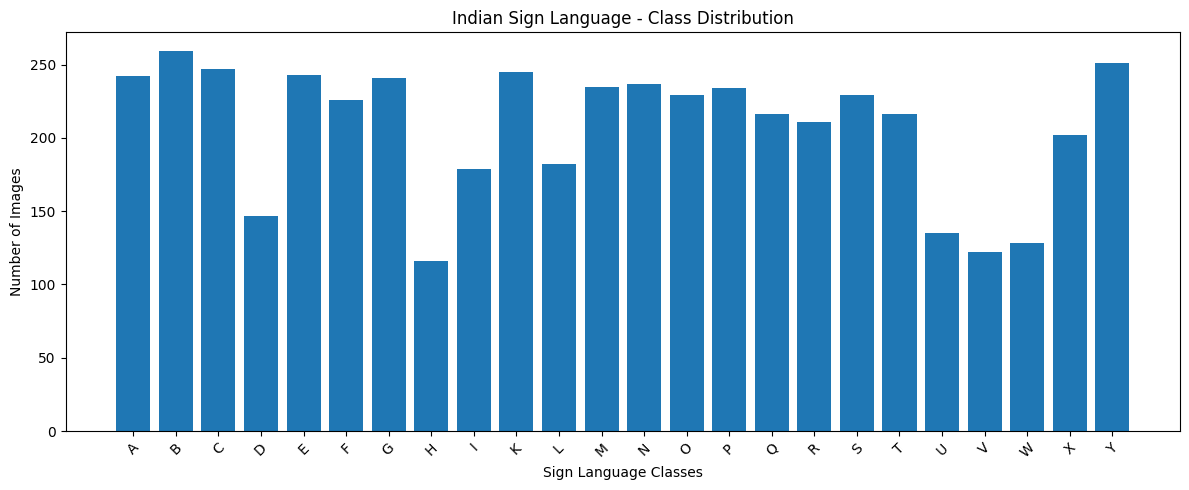

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

class_counts = {}

for class_name in classes:
    folder_path = os.path.join(dataset_path, class_name)

    image_count = len([
        file for file in os.listdir(folder_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ])

    class_counts[class_name] = image_count

df_counts = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Image_Count"]
)

print(df_counts)
print("Verified Total Images:", df_counts["Image_Count"].sum())

plt.figure(figsize=(12, 5))
plt.bar(df_counts["Class"], df_counts["Image_Count"])
plt.title("Indian Sign Language - Class Distribution")
plt.xlabel("Sign Language Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### Sample Image Visualization

This step displays one sample image from each of the
24 Indian Sign Language classes.

Objectives:
- Understand the visual appearance of hand gestures.
- Examine image quality and background conditions.
- Identify variations in lighting and positioning.
- Verify that images correspond to their class labels.


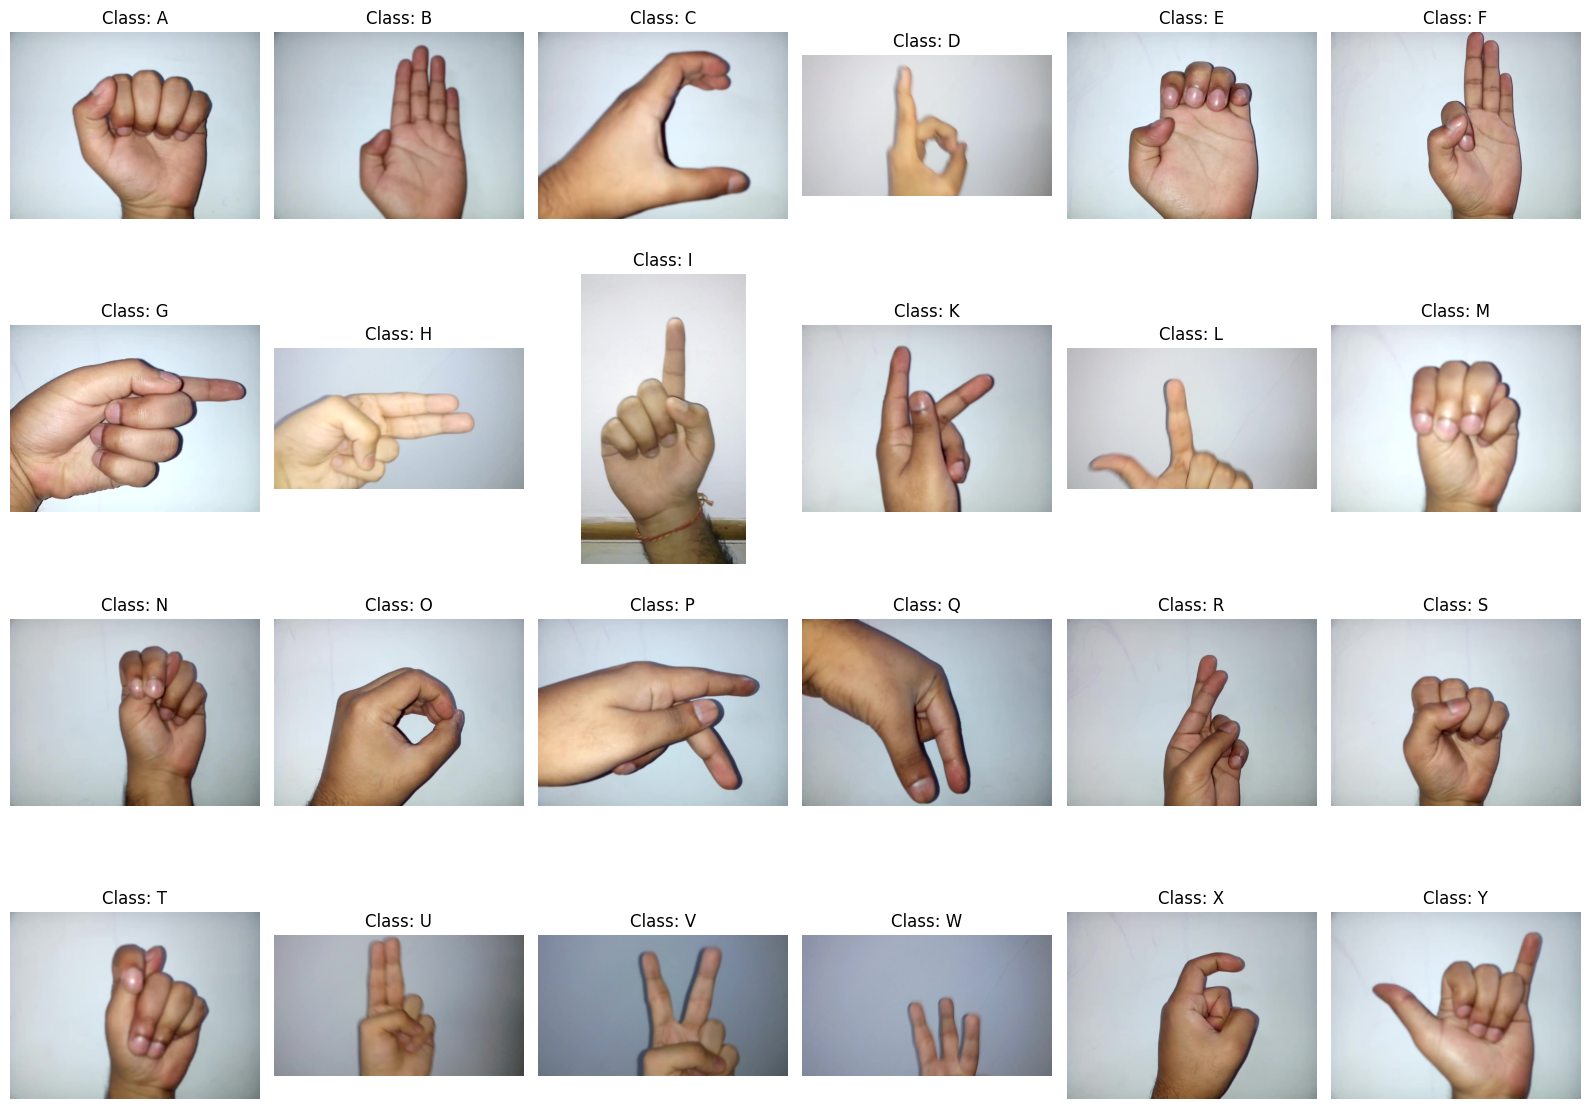

In [4]:

from PIL import Image
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(16, 12))

for i, class_name in enumerate(classes):
    folder_path = os.path.join(dataset_path, class_name)

    image_files = sorted([
        file for file in os.listdir(folder_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ])

    if not image_files:
        continue

    image_path = os.path.join(folder_path, image_files[0])
    image = Image.open(image_path).convert("RGB")

    plt.subplot(4, 6, i + 1)
    plt.imshow(image)
    plt.title(f"Class: {class_name}")
    plt.axis("off")

plt.tight_layout()
plt.show()



### Image Dimension Analysis

Objective:
- Identify the original image dimensions.
- Check whether all images have the same resolution.
- Understand the image color channels.
- Determine an appropriate input size for CNN training.


In [5]:

from PIL import Image
from collections import Counter
import os

image_sizes = []
image_modes = []

for class_name in classes:
    folder_path = os.path.join(dataset_path, class_name)

    for file in os.listdir(folder_path):
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
            image_path = os.path.join(folder_path, file)

            try:
                with Image.open(image_path) as img:
                    image_sizes.append(img.size)
                    image_modes.append(img.mode)
            except Exception as e:
                print("Error:", image_path, e)

print("Image Size Distribution:")
print(Counter(image_sizes).most_common(10))

print("\nImage Color Modes:")
print(Counter(image_modes))


Image Size Distribution:
[((640, 480), 3963), ((1920, 1088), 830), ((1088, 1920), 179)]

Image Color Modes:
Counter({'RGB': 4972})



## Image Preprocessing

The dataset contains 4,972 RGB images belonging to
24 Indian Sign Language classes.

The images have different dimensions and orientations.

Preprocessing objectives:
1. Resize images to a consistent 128 × 128 resolution.
2. Preserve aspect ratio using padding.
3. Normalize pixel values from 0–255 to 0–1.
4. Prepare images for CNN model training.


Original Size: (640, 480)
Processed Shape: (128, 128, 3)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


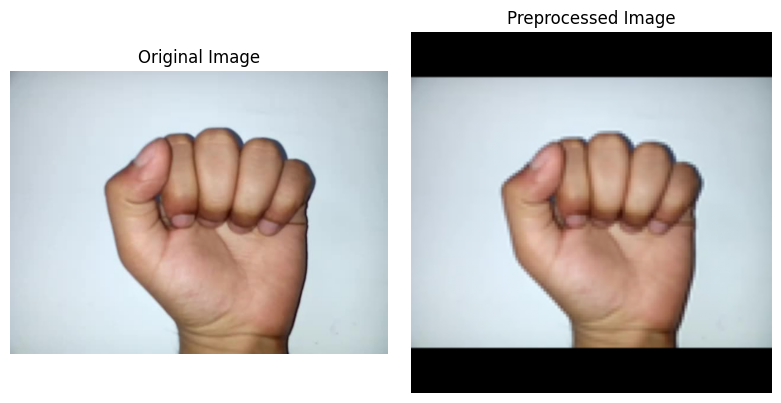

In [6]:

from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt
import os

class_name = "A"

folder_path = os.path.join(dataset_path, class_name)

image_file = sorted([
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
])[0]

image_path = os.path.join(folder_path, image_file)

image = Image.open(image_path).convert("RGB")

resized_image = ImageOps.pad(
    image,
    (128, 128),
    method=Image.Resampling.LANCZOS,
    color=(0, 0, 0)
)

image_array = np.array(resized_image) / 255.0

print("Original Size:", image.size)
print("Processed Shape:", image_array.shape)
print("Minimum Pixel Value:", image_array.min())
print("Maximum Pixel Value:", image_array.max())

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_array)
plt.title("Preprocessed Image")
plt.axis("off")

plt.tight_layout()
plt.show()



### Preprocessing the Complete Dataset

Objectives:
1. Load all images from the 24 class folders.
2. Resize images to 128 × 128 using aspect-ratio padding.
3. Normalize pixel values to the range 0–1.
4. Convert images into NumPy arrays.
5. Assign numerical labels to each class.
6. Prepare features (X) and labels (y).


In [7]:

import numpy as np
from PIL import Image, ImageOps
import os

X = []
y = []

class_to_index = {
    class_name: index
    for index, class_name in enumerate(classes)
}

for class_name in classes:
    folder_path = os.path.join(dataset_path, class_name)

    for file in os.listdir(folder_path):
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):

            image_path = os.path.join(folder_path, file)

            try:
                with Image.open(image_path) as img:
                    image = img.convert("RGB")

                    resized_image = ImageOps.pad(
                        image,
                        (128, 128),
                        method=Image.Resampling.LANCZOS,
                        color=(0, 0, 0)
                    )

                    image_array = np.asarray(
                        resized_image, dtype=np.float32
                    ) / 255.0

                    X.append(image_array)
                    y.append(class_to_index[class_name])

            except Exception as e:
                print("Error:", image_path, e)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

print("X Shape:", X.shape)
print("y Shape:", y.shape)
print("Total Classes:", len(classes))
print("Class Mapping:", class_to_index)


X Shape: (4972, 128, 128, 3)
y Shape: (4972,)
Total Classes: 24
Class Mapping: {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7, 'I': 8, 'K': 9, 'L': 10, 'M': 11, 'N': 12, 'O': 13, 'P': 14, 'Q': 15, 'R': 16, 'S': 17, 'T': 18, 'U': 19, 'V': 20, 'W': 21, 'X': 22, 'Y': 23}



## Train, Validation and Test Split

The preprocessed dataset contains 4,972 RGB images
belonging to 24 Indian Sign Language classes.

The dataset will be divided into:

- Training Data: 70%
- Validation Data: 15%
- Testing Data: 15%

Stratified splitting is used to maintain the class
distribution across all three datasets.

Random state 42 is used for reproducibility.


In [8]:

from sklearn.model_selection import train_test_split

# First split: 70% training and 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Validation Labels:", y_val.shape)
print("Testing Labels:", y_test.shape)


Training Shape: (3480, 128, 128, 3)
Validation Shape: (746, 128, 128, 3)
Testing Shape: (746, 128, 128, 3)
Training Labels: (3480,)
Validation Labels: (746,)
Testing Labels: (746,)


In [9]:
print("Total X:", len(X))
print("Total y:", len(y))
print("Total Split:", len(X_train) + len(X_val) + len(X_test))

Total X: 4972
Total y: 4972
Total Split: 4972



## Understanding CNN Architecture

Input Image (128 × 128 × 3)

Conv2D + ReLU

MaxPooling2D

Conv2D + ReLU

MaxPooling2D

Conv2D + ReLU

MaxPooling2D

Flatten

Dense + ReLU

Dropout

Dense (24) + Softmax


## Baseline CNN Model Architecture

A Convolutional Neural Network (CNN) is developed to
classify Indian Sign Language hand gestures.

The model consists of:
- Convolutional layers for feature extraction
- MaxPooling layers for dimensionality reduction
- Dense layers for classification
- Dropout for regularization
- Softmax output layer for 24-class prediction

The model uses RGB images of size 128 × 128.


In [10]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)

model = Sequential([
    Input(shape=(128, 128, 3)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(24, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,307,736 (12.62 MB)

 Trainable params: 3,307,736 (12.62 MB)

 Non-trainable params: 0 (0.00 B)


## Model Compilation

The CNN model is compiled using:

- Optimizer: Adam
- Learning Rate: 0.001
- Loss Function: Sparse Categorical Crossentropy
- Evaluation Metric: Accuracy

Adam updates model weights during training.

Sparse Categorical Crossentropy is used because
the target labels are integer-encoded from 0 to 23.

Accuracy measures the proportion of correctly
classified images.


In [11]:

from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN Model Compiled Successfully!")


CNN Model Compiled Successfully!


In [12]:

import numpy as np

print("Original Images:", len(X))
print("Original Labels:", len(y))

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

print("Training Classes:", len(np.unique(y_train)))
print("Validation Classes:", len(np.unique(y_val)))
print("Testing Classes:", len(np.unique(y_test)))


Original Images: 4972
Original Labels: 4972
Training: 3480
Validation: 746
Testing: 746
Training Classes: 24
Validation Classes: 24
Testing Classes: 24


In [13]:

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)



## Baseline CNN Model Training

The CNN model is trained using the preprocessed
Indian Sign Language images.

Training configuration:
- Epochs: 20 maximum
- Batch Size: 32
- Optimizer: Adam
- Loss: Sparse Categorical Crossentropy
- Callbacks: EarlyStopping and ReduceLROnPlateau

Training and validation metrics are recorded
for performance analysis.


In [14]:

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)


Epoch 1/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 19s 96ms/step - accuracy: 0.3546 - loss: 2.1146 - val_accuracy: 0.7735 - val_loss: 0.7976 - learning_rate: 0.0010
Epoch 2/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.7037 - loss: 0.8944 - val_accuracy: 0.9290 - val_loss: 0.2863 - learning_rate: 0.0010
Epoch 3/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8239 - loss: 0.5212 - val_accuracy: 0.9477 - val_loss: 0.1810 - learning_rate: 0.0010
Epoch 4/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.8718 - loss: 0.3699 - val_accuracy: 0.9718 - val_loss: 0.1279 - learning_rate: 0.0010
Epoch 5/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9003 - loss: 0.2800 - val_accuracy: 0.9853 - val_loss: 0.0772 - learning_rate: 0.0010
Epoch 6/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9284 - loss: 0.2042 - val_accuracy: 0.9879 - val_loss: 0.0770 - learning_rate: 0.0010
Epoch 7/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9310 - loss: 0

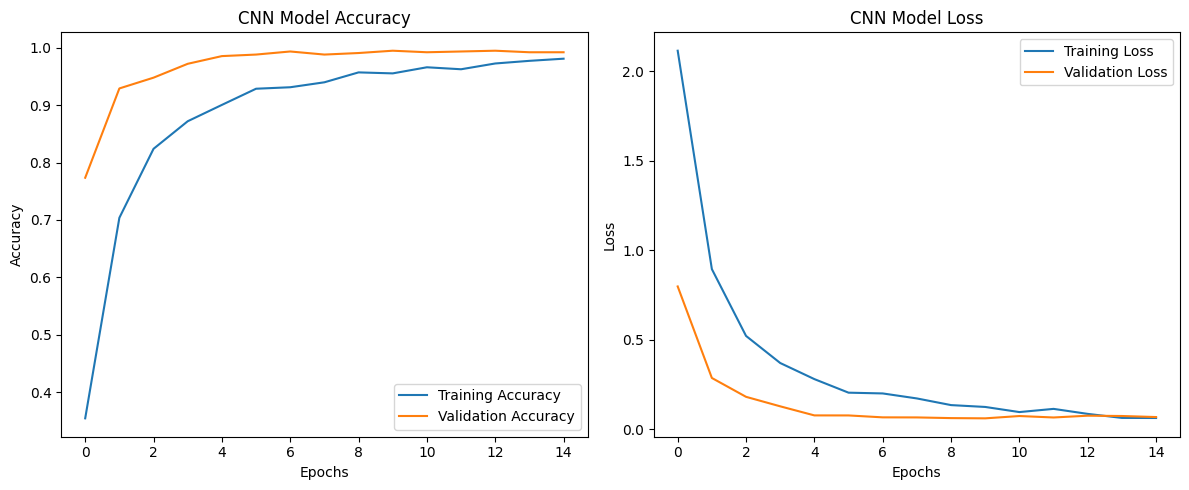

In [15]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()



## Final Model Evaluation

The trained CNN model is evaluated using the
independent test dataset.

Objectives:
- Measure test accuracy.
- Calculate test loss.
- Evaluate model generalization.
- Compare training, validation and testing performance.

The test dataset was not used during model training.


In [16]:

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9973 - loss: 0.0134
Test Accuracy: 99.73%
Test Loss: 0.0134


In [17]:

from sklearn.metrics import classification_report
import numpy as np

y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0
))


24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step
              precision    recall  f1-score   support

           A       1.00      1.00      1.00        36
           B       1.00      1.00      1.00        39
           C       1.00      1.00      1.00        37
           D       1.00      1.00      1.00        22
           E       1.00      1.00      1.00        36
           F       1.00      1.00      1.00        34
           G       1.00      1.00      1.00        36
           H       1.00      1.00      1.00        17
           I       1.00      1.00      1.00        27
           K       1.00      1.00      1.00        37
           L       1.00      0.96      0.98        28
           M       1.00      1.00      1.00        35
           N       1.00      1.00      1.00        36
           O       1.00      1.00      1.00        34
           P       1.00      1.00      1.00        35
           Q       1.00      1.00      1.00        33
           R       0.97      1.00      0.

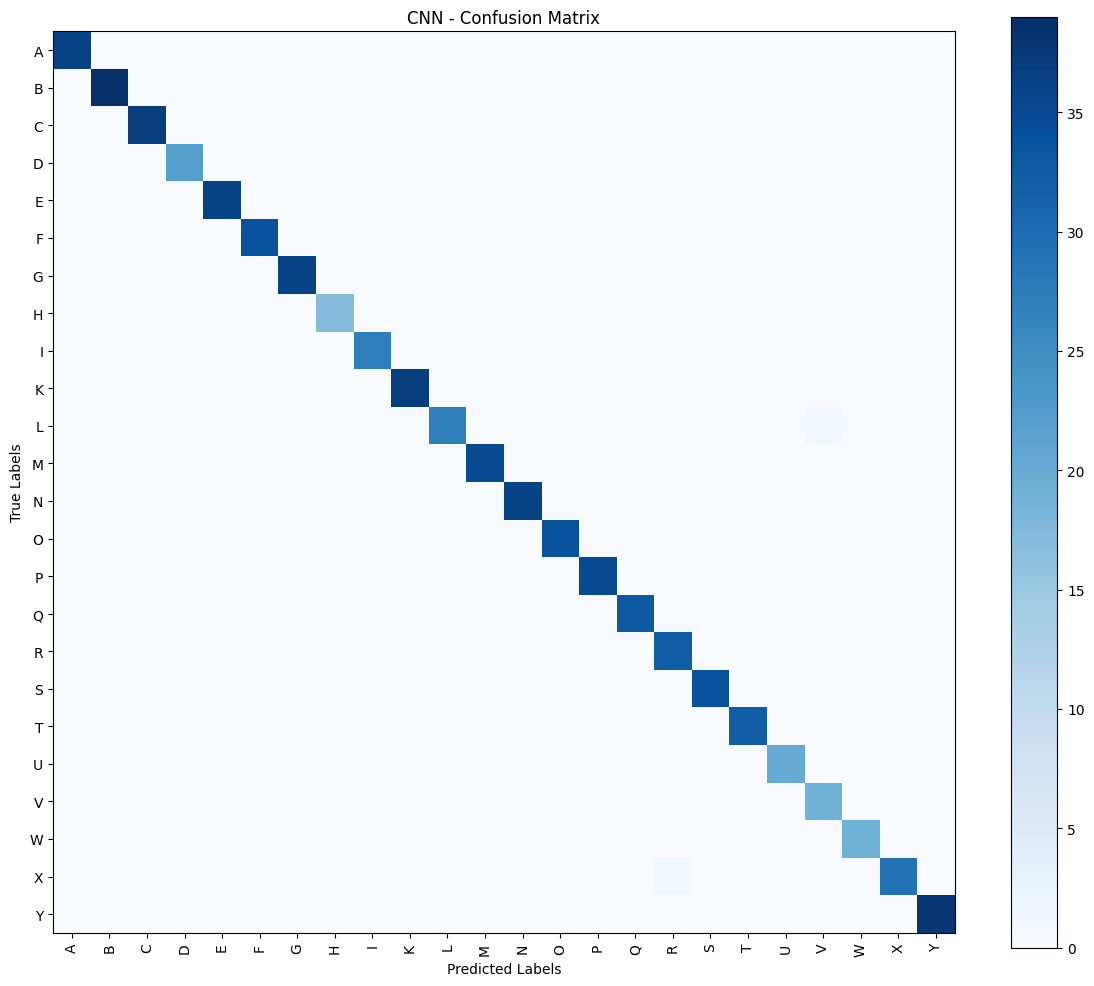

In [18]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(classes))
)

plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks(range(len(classes)), classes, rotation=90)
plt.yticks(range(len(classes)), classes)

plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("CNN - Confusion Matrix")

plt.tight_layout()
plt.show()


Total Test Images: 746
Correct Predictions: 744
Incorrect Predictions: 2


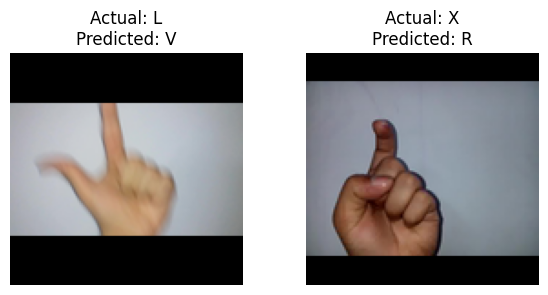

In [19]:

wrong_indices = np.where(y_pred != y_test)[0]

print("Total Test Images:", len(y_test))
print("Correct Predictions:", len(y_test) - len(wrong_indices))
print("Incorrect Predictions:", len(wrong_indices))

plt.figure(figsize=(12, 8))

for i, idx in enumerate(wrong_indices[:12]):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[idx])
    plt.title(
        f"Actual: {classes[y_test[idx]]}\n"
        f"Predicted: {classes[y_pred[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


In [20]:

print("=" * 45)
print("INDIAN SIGN LANGUAGE - CNN EVALUATION")
print("=" * 45)

print("Model: Baseline CNN")
print("Total Classes:", len(classes))
print("Test Samples:", len(X_test))

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

print("Correct Predictions:", np.sum(y_pred == y_test))
print("Incorrect Predictions:", np.sum(y_pred != y_test))


INDIAN SIGN LANGUAGE - CNN EVALUATION
Model: Baseline CNN
Total Classes: 24
Test Samples: 746
Test Accuracy: 99.73%
Test Loss: 0.0134
Correct Predictions: 744
Incorrect Predictions: 2


In [21]:

import os
import json

save_dir = "/content/drive/MyDrive/AI_pro_indsignlan/models"

os.makedirs(save_dir, exist_ok=True)

model.save(
    os.path.join(save_dir, "isl_cnn_model.keras")
)

with open(
    os.path.join(save_dir, "class_mapping.json"),
    "w"
) as f:
    json.dump(class_to_index, f, indent=4)

print("CNN Model Saved Successfully!")
print("Class Mapping Saved Successfully!")


CNN Model Saved Successfully!
Class Mapping Saved Successfully!



# Final Project Conclusion

## Project Title
Indian Sign Language Recognition Using Deep Learning (CNN)

**Project ID:** PRAICP-1000-IndiSignLang  
**Domain:** Artificial Intelligence | Deep Learning  
**Algorithm:** Convolutional Neural Network (CNN)

---

## 1. Project Overview

This project developed a Convolutional Neural Network (CNN)
to recognize Indian Sign Language (ISL) alphabet gestures
from images.

The objective was to preprocess hand gesture images,
extract meaningful visual features, and accurately classify
them into their corresponding alphabet categories.

The project demonstrates the application of deep learning
to communication accessibility.

## 2. Dataset Summary

- Original Dataset: 4,972 image filenames
- Number of Classes: 24
- Classes: A–Y, excluding J and Z
- Image Color Format: RGB
- Original Image Dimensions:
  - 640 × 480
  - 1920 × 1088
  - 1088 × 1920
- Model Input Size: 128 × 128 × 3
- Normalization: Pixel values scaled from 0–255 to 0–1

The dataset contained different image resolutions and
unequal numbers of samples across classes.

Aspect-ratio-preserving resizing with padding was used
to maintain hand gesture proportions.

## 3. Project Workflow

1. Business Understanding
2. Dataset Loading and Inspection
3. Exploratory Data Analysis (EDA)
4. Class Distribution Analysis
5. Sample Image Visualization
6. Image Dimension and Color Mode Analysis
7. Image Resizing and Normalization
8. Numerical Label Encoding
9. Stratified Train, Validation and Test Split
10. CNN Architecture Development
11. Model Compilation and Training
12. Training and Validation Performance Analysis
13. Final Test Evaluation
14. Classification Report and Confusion Matrix
15. Misclassification Analysis
16. Model Saving

## 4. Model Architecture

The baseline CNN consisted of:

- Input Layer: 128 × 128 × 3
- Conv2D: 32 filters, 3 × 3, ReLU
- MaxPooling2D: 2 × 2
- Conv2D: 64 filters, 3 × 3, ReLU
- MaxPooling2D: 2 × 2
- Conv2D: 128 filters, 3 × 3, ReLU
- MaxPooling2D: 2 × 2
- Flatten Layer
- Dense Layer: 128 neurons, ReLU
- Dropout: 0.5
- Output Layer: 24 neurons, Softmax

Total Trainable Parameters: 3,307,736

### Training Configuration

- Optimizer: Adam
- Initial Learning Rate: 0.001
- Loss Function: Sparse Categorical Crossentropy
- Evaluation Metric: Accuracy
- Batch Size: 32
- Maximum Epochs: 20
- Callbacks:
  - EarlyStopping
  - ReduceLROnPlateau

## 5. Final Model Performance

| Evaluation Metric | Result |
|---|---:|
| Test Accuracy | 99.73% |
| Test Loss | 0.0134 |
| Test Samples | 746 |
| Correct Predictions | 744 |
| Incorrect Predictions | 2 |
| Number of Classes | 24 |

The baseline CNN correctly classified 744 out of
746 test images, achieving 99.73% test accuracy.

## 6. Misclassification Analysis

Only two images were incorrectly classified:

| Actual Class | Predicted Class |
|---|---|
| L | V |
| X | R |

The errors indicate that certain hand gestures
with similar visual characteristics may be
challenging for the CNN model.

The confusion matrix showed that nearly all
predictions were concentrated along the main diagonal,
indicating strong classification performance.

## 7. Key Findings

1. CNN successfully learned discriminative visual
   features from Indian Sign Language images.

2. Image preprocessing standardized different
   image resolutions while preserving hand proportions.

3. Stratified dataset splitting helped maintain
   class representation across training,
   validation, and testing datasets.

4. The CNN achieved 99.73% accuracy on the
   held-out test dataset.

5. Only two misclassifications were identified,
   demonstrating strong performance on this dataset.

6. EarlyStopping and ReduceLROnPlateau were used
   to control training and learning-rate adjustments.

## 8. Project Limitations

- The dataset contains only 24 alphabet classes.
- J and Z are not represented.
- Some image files were unreadable during inspection.
- The model was evaluated on a dataset with relatively
  consistent image backgrounds.
- Performance on real-time camera images has not
  been evaluated.
- Duplicate-image and signer-independent validation
  have not yet been completed.

Therefore, the reported accuracy reflects performance
on the current held-out test split and should not be
interpreted as guaranteed real-world accuracy.


## 9. Final Conclusion

The Indian Sign Language Recognition project
successfully demonstrated the use of deep learning
for multiclass hand gesture classification.

The developed CNN achieved a test accuracy of 99.73%,
correctly predicting 744 out of 746 test images
across 24 alphabet classes.

The results demonstrate that CNN-based image
classification can effectively learn visual patterns
associated with Indian Sign Language gestures
under the evaluated dataset conditions.

Although further validation is required for real-world
deployment, the project provides a strong foundation
for developing accessible sign language recognition
applications.

**Final Model:** Baseline CNN  
**Final Test Accuracy:** 99.73%  
**Project Status:** Completed — Baseline Model Evaluation
